In [1]:
import os, json, pathlib
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models, callbacks
!pip install pyngrok
from pyngrok import ngrok

# ----- settings you can change -----
IMG = 224            # image size the model sees
BATCH = 32
STEPS= 95230
QUICK_TEST = False    # True = use only 200 images per class to test the code fast. Set False for real training.
MERGE = {"Animals": "Animal"}   # folders that mean the same thing -> one class

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
ROOT = None
for dp, dirs, files in os.walk("/kaggle/input"):
    if os.path.basename(dp) == "My Dataset" and len(dirs) >= 5:
        ROOT = dp
        break

print("ROOT:", ROOT)
print("Top-level folders:", sorted(os.listdir(ROOT)))

ROOT: /kaggle/input/datasets/harshkumar970/my-dataset/My Dataset
Top-level folders: ['Animal', 'Animals', 'Disaster', 'Human', 'Plants', 'Vehical']


In [3]:
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

rows = []
for p in pathlib.Path(ROOT).rglob("*"):
    if p.is_file() and p.suffix.lower() in VALID_EXT:
        top = p.relative_to(ROOT).parts[0]          # first folder name = class
        rows.append((str(p), MERGE.get(top, top)))

df = pd.DataFrame(rows, columns=["path", "label"])
print("Total images:", len(df))
print(df.label.value_counts())

Total images: 136044
label
Animal      52019
Plants      37239
Human       17643
Vehical     15586
Disaster    13557
Name: count, dtype: int64


In [4]:
def check(path):
    try:
        with Image.open(path) as im:
            im.load()                       # fully decodes the image
            if min(im.size) < 32:
                return "too_small"
        return "ok"
    except Exception:
        return "corrupt"

with ThreadPoolExecutor(max_workers=8) as ex:
    df["status"] = list(ex.map(check, df.path, chunksize=64))

print(df.status.value_counts())

df[df.status != "ok"].to_csv("/kaggle/working/bad_images.csv", index=False)
df = df[df.status == "ok"].drop(columns="status").reset_index(drop=True)
df.to_csv("/kaggle/working/clean_files.csv", index=False)
print("Clean images:", len(df))

status
ok         136042
corrupt         2
Name: count, dtype: int64
Clean images: 136042


In [5]:
if QUICK_TEST:
    df = df.groupby("label", group_keys=False).apply(lambda g: g.sample(min(len(g), 200), random_state=42)).reset_index(drop=True)
    print("QUICK TEST MODE: using", len(df), "images")

classes = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM = len(classes)

json.dump(classes, open("/kaggle/working/classes.json", "w"))
print(NUM, "classes:", classes)

5 classes: ['Animal', 'Disaster', 'Human', 'Plants', 'Vehical']


In [6]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=42)

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))
print(train_df.label.value_counts())

Train: 95229 | Val: 20406 | Test: 20407
label
Animal      36413
Plants      26067
Human       12350
Vehical     10910
Disaster     9489
Name: count, dtype: int64


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

# class weights as a plain tensor (index = class number)
counts = train_df.label.astype(str).value_counts()
CW = tf.constant([len(train_df) / (NUM * counts[c]) for c in classes], dtype=tf.float32)

def make_ds(d, training, weighted=False):
    paths  = np.array(d.path.tolist(), dtype=str)
    labels = np.array([class_to_idx[str(l)] for l in d.label.tolist()], dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(d), seed=42)

    def load(p, y):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img = tf.image.resize(img, (IMG, IMG))
        img.set_shape((IMG, IMG, 3))
        y = tf.cast(y, tf.int32)
        if weighted:
            return img, y, tf.gather(CW, y)      # (image, label, sample weight)
        return img, y

    return ds.map(load, num_parallel_calls=AUTOTUNE).ignore_errors().batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, True, weighted=True)
val_ds   = make_ds(val_df, False)
test_ds  = make_ds(test_df, False)

print(train_ds.element_spec)

(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))


In [8]:
aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

inp = layers.Input((IMG, IMG, 3))
x = aug(inp)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(NUM, activation="softmax")(x)
model = models.Model(inp, out)

print("Output classes:", model.output_shape[-1])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Output classes: 5


In [9]:
import keras
keras.config.disable_traceback_filtering()

In [10]:
def new_cb():
    return [
        callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
        callbacks.ModelCheckpoint("/kaggle/working/best_model.keras", monitor="val_accuracy", save_best_only=True),
    ]
EPOCHS = 10
# EPOCHS = 2 if QUICK_TEST else 10

# Phase 1: train only the new top layer
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=new_cb())

# Phase 2: fine-tune the last 30 layers with a very small learning rate
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=new_cb())

model.save("/kaggle/working/final_model.keras")
print("Model saved")

Epoch 1/10
   2976/Unknown 263s 85ms/step - accuracy: 0.8436 - loss: 0.4980

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2976/2976 ━━━━━━━━━━━━━━━━━━━━ 316s 103ms/step - accuracy: 0.8823 - loss: 0.3983 - val_accuracy: 0.9311 - val_loss: 0.2258 - learning_rate: 0.0010
Epoch 2/10
2976/2976 ━━━━━━━━━━━━━━━━━━━━ 302s 102ms/step - accuracy: 0.9003 - loss: 0.3457 - val_accuracy: 0.9386 - val_loss: 0.2022 - learning_rate: 0.0010
Epoch 3/10
2976/2976 ━━━━━━━━━━━━━━━━━━━━ 303s 102ms/step - accuracy: 0.9005 - loss: 0.3448 - val_accuracy: 0.9339 - val_loss: 0.2172 - learning_rate: 0.0010
Epoch 4/10
2976/2976 ━━━━━━━━━━━━━━━━━━━━ 304s 102ms/step - accuracy: 0.9015 - loss: 0.3462 - val_accuracy: 0.9304 - val_loss: 0.2268 - learning_rate: 0.0010
Epoch 5/10
2976/2976 ━━━━━━━━━━━━━━━━━━━━ 303s 102ms/step - accuracy: 0.9089 - loss: 0.3163 - val_accuracy: 0.9306 - val_loss: 0.2153 - learning_rate: 3.0000e-04
Epoch 1/10
2976/2976 ━━━━━━━━━━━━━━━━━━━━ 314s 104ms/step - accuracy: 0.9227 - loss: 0.2636 - val_accuracy: 0.9431 - val_loss: 0.1760 - learning_rate: 1.0000e-05
Epoch 2/10
2976/2976 ━━━━━━━━━━━━━━━━━━━━ 304s 102ms/st

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from itertools import cycle
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# predictions on the test set (one pass, same order for labels and predictions)
y_true, y_pred = [], []
for x, y in test_ds:
    y_pred.extend(np.argmax(model.predict_on_batch(x), axis=1))
    y_true.extend(y.numpy())
y_true, y_pred = np.array(y_true), np.array(y_pred)

test_acc = (y_true == y_pred).mean()
cm = confusion_matrix(y_true, y_pred, labels=range(NUM))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
f1 = f1_score(y_true, y_pred, labels=range(NUM), average=None, zero_division=0)

print(f"Test accuracy: {test_acc:.4f}  |  Macro F1: {f1.mean():.4f}")
print(classification_report(y_true, y_pred, labels=range(NUM), target_names=classes, zero_division=0))

# training history (both phases joined)
try:
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
    split_at = len(h1.history["loss"])
except NameError:
    hist = model.history.history        # only the last phase if h1/h2 were not saved
    split_at = None
epochs = range(1, len(hist["loss"]) + 1)

Test accuracy: 0.9602  |  Macro F1: 0.9467
              precision    recall  f1-score   support

      Animal       0.99      0.98      0.99      7803
    Disaster       0.93      0.85      0.89      2033
       Human       0.86      0.97      0.91      2647
      Plants       0.97      0.95      0.96      5586
     Vehical       0.98      0.99      0.98      2338

    accuracy                           0.96     20407
   macro avg       0.95      0.95      0.95     20407
weighted avg       0.96      0.96      0.96     20407



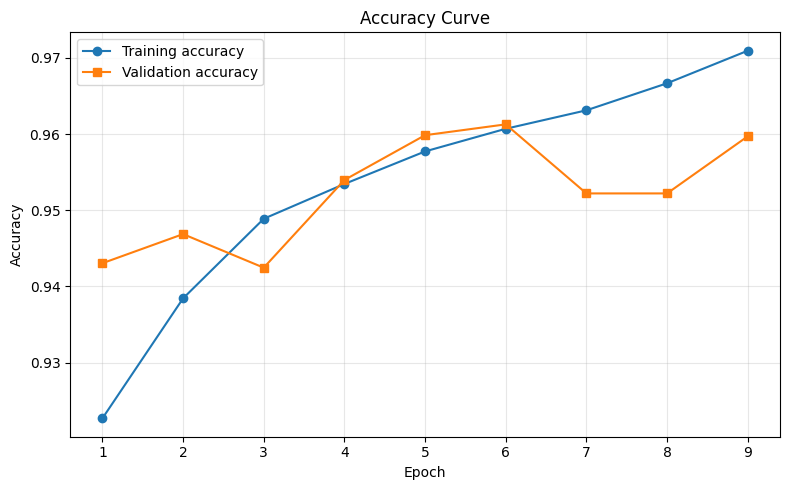

In [12]:
# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, hist["accuracy"], "o-", label="Training accuracy")
plt.plot(epochs, hist["val_accuracy"], "s-", label="Validation accuracy")
if split_at:
    plt.axvline(split_at + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.title("Accuracy Curve"); plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("/kaggle/working/accuracy_curve.png", dpi=300)
plt.show()

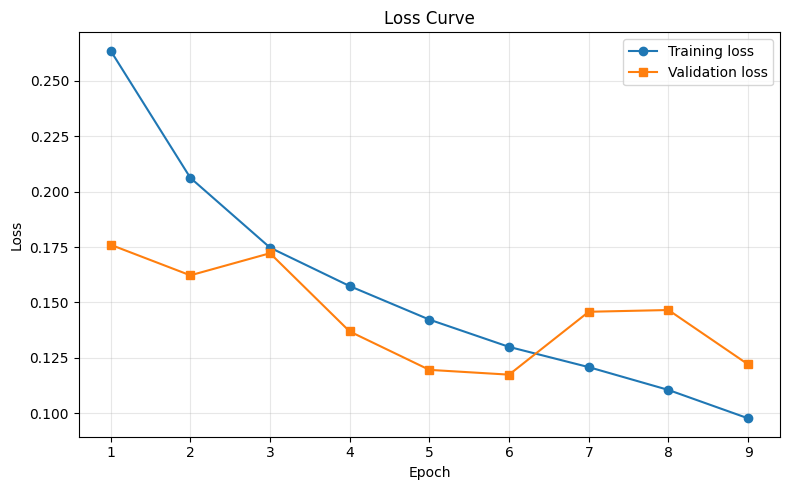

In [13]:
# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, hist["loss"], "o-", label="Training loss")
plt.plot(epochs, hist["val_loss"], "s-", label="Validation loss")
if split_at:
    plt.axvline(split_at + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.title("Loss Curve"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("/kaggle/working/loss_curve.png", dpi=300)
plt.show()

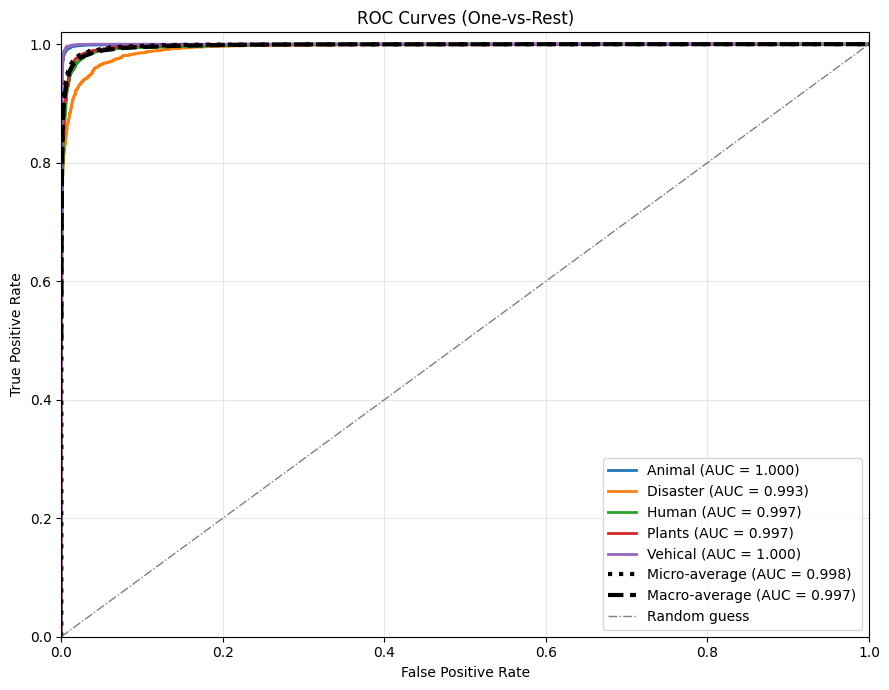

AUC per class: {'Animal': np.float64(0.9995), 'Disaster': np.float64(0.9933), 'Human': np.float64(0.9966), 'Plants': np.float64(0.9973), 'Vehical': np.float64(0.9996)}
Macro AUC: 0.9973 | Micro AUC: 0.9978


In [14]:
# ROC Curve
# ---- 1) probabilities and true labels in ONE pass (same order) ----
y_true, y_prob = [], []
for x, y in test_ds:
    y_prob.append(model.predict_on_batch(x))
    y_true.extend(y.numpy())
y_prob = np.vstack(y_prob)
y_true = np.array(y_true)

# one-hot version of the labels (needed for one-vs-rest)
y_bin = label_binarize(y_true, classes=range(NUM))

# ---- 2) ROC and AUC per class ----
fpr, tpr, roc_auc = {}, {}, {}
for i in range(NUM):
    fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# micro-average (pools all classes together)
fpr["micro"], tpr["micro"], _ = roc_curve(y_bin.ravel(), y_prob.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# macro-average (average of the per-class curves)
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(NUM)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(NUM):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= NUM
fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
roc_auc["macro"] = auc(all_fpr, mean_tpr)

# ---- 3) plot ----
plt.figure(figsize=(9, 7))
colors = cycle(["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink"])
for i, c in zip(range(NUM), colors):
    plt.plot(fpr[i], tpr[i], color=c, lw=2, label=f"{classes[i]} (AUC = {roc_auc[i]:.3f})")

plt.plot(fpr["micro"], tpr["micro"], "k:", lw=3, label=f"Micro-average (AUC = {roc_auc['micro']:.3f})")
plt.plot(fpr["macro"], tpr["macro"], "k--", lw=3, label=f"Macro-average (AUC = {roc_auc['macro']:.3f})")
plt.plot([0, 1], [0, 1], color="gray", lw=1, linestyle="-.", label="Random guess")

plt.xlim([0, 1]); plt.ylim([0, 1.02])
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves (One-vs-Rest)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/roc_curve.png", dpi=300)
plt.show()

print("AUC per class:", {classes[i]: round(roc_auc[i], 4) for i in range(NUM)})
print("Macro AUC:", round(roc_auc["macro"], 4), "| Micro AUC:", round(roc_auc["micro"], 4))

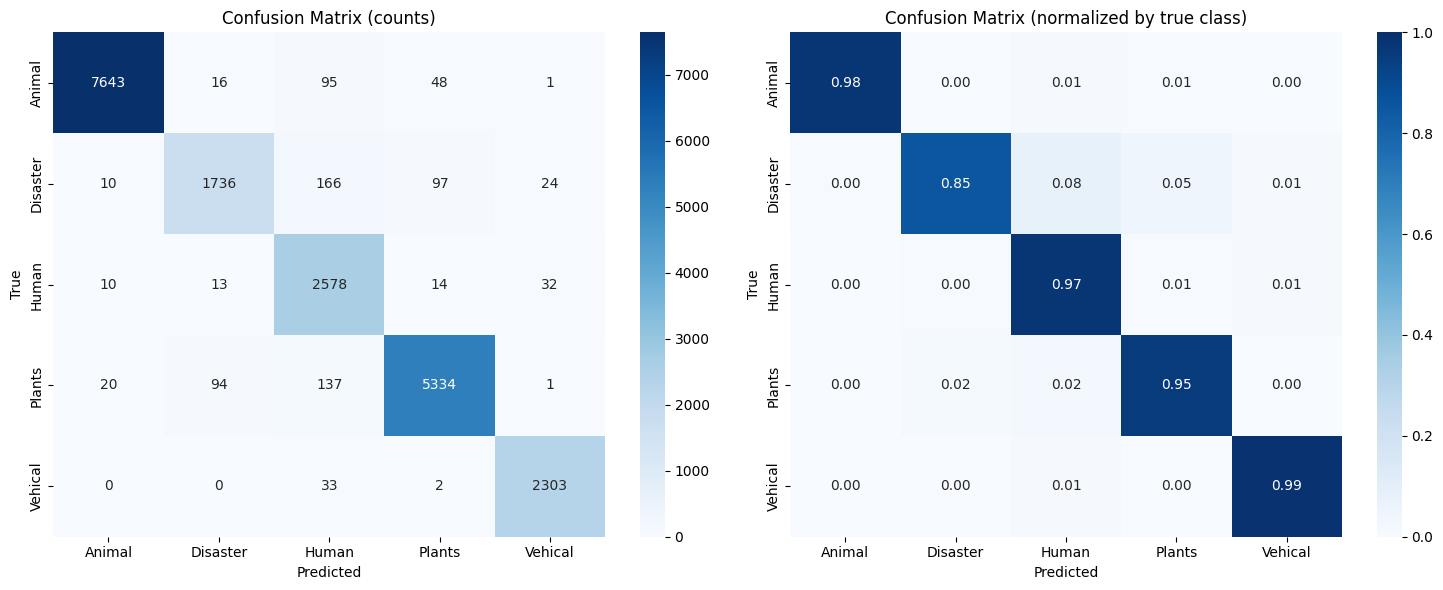

In [15]:
# Confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set_title("Confusion Matrix (counts)")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set_title("Confusion Matrix (normalized by true class)")

for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.savefig("/kaggle/working/confusion_matrix.png", dpi=300)
plt.show()

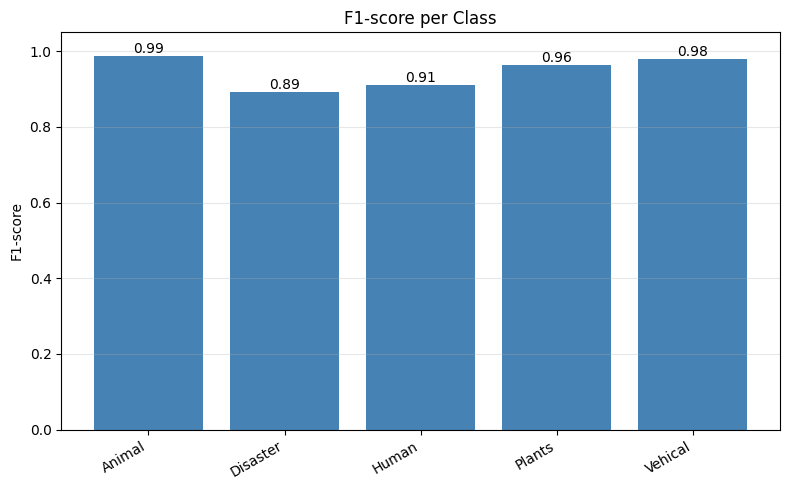

In [16]:
# F1 Chart
plt.figure(figsize=(8, 5))
bars = plt.bar(classes, f1, color="steelblue")
plt.bar_label(bars, fmt="%.2f")
plt.ylim(0, 1.05); plt.title("F1-score per Class"); plt.ylabel("F1-score")
plt.xticks(rotation=30, ha="right"); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("/kaggle/working/f1_per_class.png", dpi=300)
plt.show()

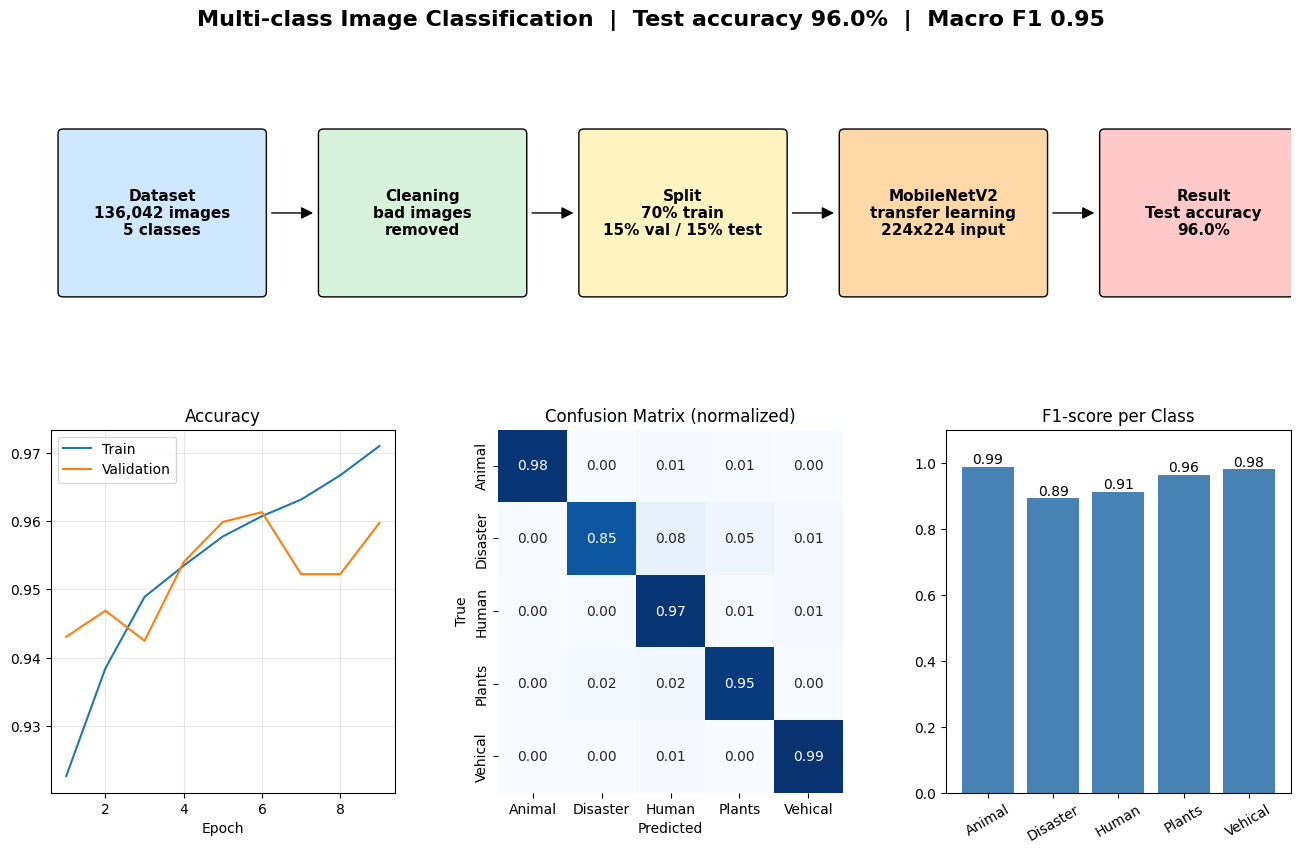

In [17]:
# Graphical abtract
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.6], hspace=0.35, wspace=0.3)

# ---- top: pipeline ----
axp = fig.add_subplot(gs[0, :]); axp.axis("off"); axp.set_xlim(0, 100); axp.set_ylim(0, 20)
steps = [
    (f"Dataset\n{len(df):,} images\n{NUM} classes", "#cfe8ff"),
    ("Cleaning\nbad images\nremoved",              "#d8f3dc"),
    ("Split\n70% train\n15% val / 15% test",       "#fff3bf"),
    (f"MobileNetV2\ntransfer learning\n{IMG}x{IMG} input", "#ffd8a8"),
    (f"Result\nTest accuracy\n{test_acc*100:.1f}%", "#ffc9c9"),
]
w, gap = 16, 5
for i, (txt, col) in enumerate(steps):
    x = i * (w + gap) + 1
    axp.add_patch(FancyBboxPatch((x, 3), w, 14, boxstyle="round,pad=0.4", fc=col, ec="black"))
    axp.text(x + w/2, 10, txt, ha="center", va="center", fontsize=11, fontweight="bold")
    if i < len(steps) - 1:
        axp.add_patch(FancyArrowPatch((x + w + 0.6, 10), (x + w + gap - 0.6, 10),
                                      arrowstyle="-|>", mutation_scale=18, color="black"))

# ---- bottom: three result plots ----
a1 = fig.add_subplot(gs[1, 0])
a1.plot(epochs, hist["accuracy"], label="Train"); a1.plot(epochs, hist["val_accuracy"], label="Validation")
a1.set_title("Accuracy"); a1.set_xlabel("Epoch"); a1.legend(); a1.grid(alpha=0.3)

a2 = fig.add_subplot(gs[1, 1])
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=classes, yticklabels=classes, ax=a2)
a2.set_title("Confusion Matrix (normalized)"); a2.set_xlabel("Predicted"); a2.set_ylabel("True")

a3 = fig.add_subplot(gs[1, 2])
b = a3.bar(classes, f1, color="steelblue"); a3.bar_label(b, fmt="%.2f")
a3.set_ylim(0, 1.1); a3.set_title("F1-score per Class"); a3.tick_params(axis="x", rotation=30)

fig.suptitle(f"Multi-class Image Classification  |  Test accuracy {test_acc*100:.1f}%  |  Macro F1 {f1.mean():.2f}",
             fontsize=16, fontweight="bold")
plt.savefig("/kaggle/working/graphical_abstract.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# ===== Plant Classifier API: Flask + ngrok (one cell) =====
!pip install -q flask flask-cors pyngrok pillow
ngrok.set_auth_token("3LlxzzxVUZbVZlg8B5eysBhu7G9_6nGgnAYpdkuGMcTCJrUDt")

import io, os, json, time, socket, threading, requests
import numpy as np
from PIL import Image
from flask import Flask, request, jsonify
from flask_cors import CORS
from pyngrok import ngrok
import tensorflow as tf

# ---------- 1) Model (use the one in memory, else load from file) ----------
try:
    model
except NameError:
    MODEL_PATH = "/kaggle/working/best_model.keras"   # change if your file is named differently
    model = tf.keras.models.load_model(MODEL_PATH)

# image size is read from the model itself, so it always matches training
img_height, img_width = model.input_shape[1], model.input_shape[2]
NUM_CLASSES = model.output_shape[-1]

# ---------- 2) Class names (must be in the SAME order as training) ----------
class_names = None
for getter in (
    lambda: list(train_ds.class_names),
    lambda: list(classes),
    lambda: json.load(open("/kaggle/working/classes.json")),
    lambda: json.load(open("/kaggle/working/class_names.json")),
):
    try:
        class_names = getter()
        break
    except Exception:
        pass

if class_names is None:
    raise RuntimeError("Class names not found. Set: class_names = [...] in the same order as training.")

assert len(class_names) == NUM_CLASSES, f"{len(class_names)} names but model outputs {NUM_CLASSES}"
print(f"Model input: {img_height}x{img_width}, {NUM_CLASSES} classes")

# ---------- 3) ngrok token (use Kaggle Secrets, never paste the token here) ----------
try:
    from kaggle_secrets import UserSecretsClient
    ngrok.set_auth_token(UserSecretsClient().get_secret("NGROK_TOKEN"))
except Exception as e:
    print("Secret NGROK_TOKEN not found, using existing ngrok config:", e)

# ---------- 4) Flask app ----------
app = Flask(__name__)
CORS(app)

def preprocess(img_bytes):
    img = Image.open(io.BytesIO(img_bytes)).convert("RGB").resize((img_width, img_height))
    arr = np.array(img, dtype="float32")        # keep 0-255 (model has preprocessing inside)
    return np.expand_dims(arr, axis=0)

@app.route("/")
def home():
    return "Classifier API is running"

@app.route("/health")
@app.route("/api/health")
@app.route("/ping")
def health():
    return jsonify({"status": "ok", "ok": True})

@app.route("/predict", methods=["POST", "OPTIONS"])
@app.route("/api/predict", methods=["POST", "OPTIONS"])
def predict():
    if request.method == "OPTIONS":
        return ("", 204)

    f = request.files.get("file") or request.files.get("image")
    if f is None:
        return jsonify({"error": "No file uploaded"}), 400

    try:
        probs = model.predict(preprocess(f.read()), verbose=0)[0]
        top = np.argsort(probs)[::-1][:3]
        top3 = [{
            "class": class_names[int(i)],
            "label": class_names[int(i)],
            "name": class_names[int(i)],
            "confidence": float(probs[i]),
            "probability": float(probs[i]),
            "score": float(probs[i]),
        } for i in top]

        best = top3[0]
        return jsonify({
            "prediction": best["class"],
            "predicted_class": best["class"],
            "class": best["class"],
            "label": best["class"],
            "confidence": best["confidence"],
            "probability": best["confidence"],
            "top3": top3,
            "top_3": top3,
            "top_predictions": top3,
            "predictions": top3,
        })
    except Exception as e:
        return jsonify({"error": str(e)}), 500

@app.after_request
def add_headers(resp):
    resp.headers["Access-Control-Allow-Origin"] = "*"
    resp.headers["Access-Control-Allow-Headers"] = "*"
    resp.headers["Access-Control-Allow-Methods"] = "GET, POST, OPTIONS"
    return resp

# ---------- 5) Start server on a free port ----------
def free_port():
    s = socket.socket()
    s.bind(("", 0))
    p = s.getsockname()[1]
    s.close()
    return p

PORT = free_port()
threading.Thread(
    target=lambda: app.run(host="0.0.0.0", port=PORT, use_reloader=False),
    daemon=True
).start()
time.sleep(3)
print("Local test:", requests.get(f"http://127.0.0.1:{PORT}/").text)

# ---------- 6) Public URL ----------
ngrok.kill()
public_url = ngrok.connect(PORT).public_url
print("\n✅ Your API URL:", public_url)
print("Predict endpoint:", public_url + "/predict")

Model input: 224x224, 5 classes
Secret NGROK_TOKEN not found, using existing ngrok config: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 143061719 and label NGROK_TOKEN.'], 'error': {'code': 5}, 'wasSuccessful': False}.
 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:36613
 * Running on http://172.19.2.2:36613
Press CTRL+C to quit
127.0.0.1 - - [07/Nov/2026 11:16:09] "GET / HTTP/1.1" 200 -


Local test: Classifier API is running

✅ Your API URL: https://fabric-oval-comfy.ngrok-free.dev
Predict endpoint: https://fabric-oval-comfy.ngrok-free.dev/predict
